    患者ID        年龄 性别  地区       就诊日期 疾病类型       诊断日期 疾病严重程度  治疗方案  治疗结果  ...  \
0  20413  0.444444  女  重庆 2023-04-04   感冒 2023-04-25    不严重    放疗  病情稳定  ...   
1  59255  0.868687  男  成都 2022-10-30   骨折 2022-12-14     中度    放疗  病情稳定  ...   
2  66021  0.333333  男  深圳 2022-11-03  高血压 2023-04-16    不严重    化疗    康复  ...   
3  21594  0.111111  男  杭州 2022-08-07  糖尿病 2023-05-19     轻度  物理疗法  病情稳定  ...   
4  14858  0.767677  女  广州 2022-08-18  高血压 2022-11-28     严重  手术治疗  病情稳定  ...   

   检查项目   检查结果 参考范围      体重        身高  吸烟情况 饮酒情况  遗传病史   诊断延迟     病程  
0   尿常规  105.0   正常  0.3375  0.733333     是   偶尔     是   21.0  495.0  
1   胆固醇  157.0   正常  0.4875  0.416667     是   戒酒     是   45.0  627.0  
2  核磁共振  126.0   偏高  0.9375  0.983333     否   偶尔     否  164.0  504.0  
3   尿常规   91.0   正常  0.4250  0.900000     否    否     否  285.0  471.0  
4    血压   98.0   偏低  0.6250  0.116667     否    是     否  102.0  643.0  

[5 rows x 24 columns]
删除的重复行数: 0


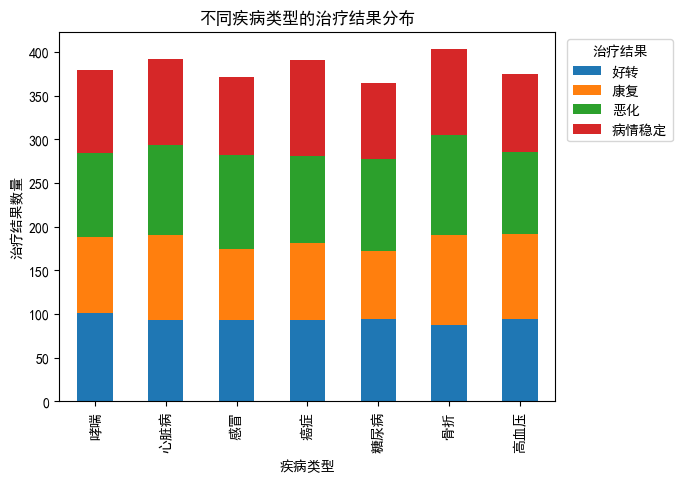

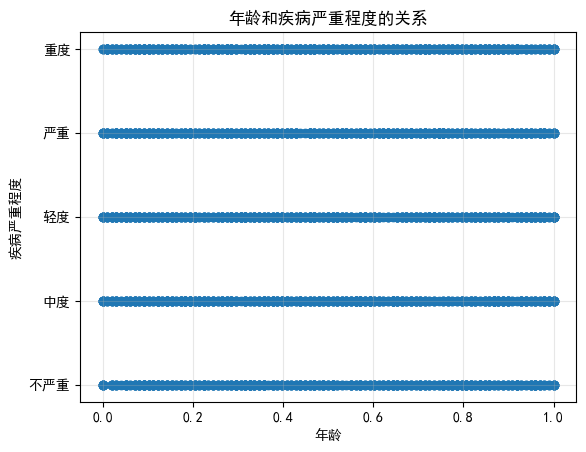

In [11]:
import pandas as pd

# 加载数据集并指定编码
data =pd.read_csv('2.1.4_cleaned_data.csv', encoding='utf8')

# # 查看数据类型
# print(data.dtypes)
# # 查看表结构
# print(data.info())

# 显示每一列的空缺值数量
# print(data.isnull().sum())

# 规范日期格式
data['就诊日期'] = pd.to_datetime(data['就诊日期'])
data['诊断日期'] = pd.to_datetime(data['诊断日期'])

# 重命名列
data.rename(columns={'病人ID': '患者ID'}, inplace=True)

# 查看修改后的表结构
print(data.head())

from datetime import datetime

# 增加诊断延迟和病程
today = datetime.now().date()
data['诊断延迟'] = (data['诊断日期'] - data['就诊日期']).dt.days
data['病程'] = (pd.Timestamp(today) - data['诊断日期']).dt.days

# 删除不合理的数据
data = data[(data['诊断延迟'] >= 0) & (data['年龄'] > 0) & (data['年龄'] < 120)]

# 查看修改后的数据
# print(data.describe())

# 删除重复值并记录删除的行数
initial_rows = data.shape[0]
data.drop_duplicates(inplace=True)
deleted_rows = initial_rows - data.shape[0]

print(f'删除的重复行数: {deleted_rows}')

from sklearn.preprocessing import MinMaxScaler

# 对需要归一化的列进行处理
scaler = MinMaxScaler()
columns_to_normalize = ['年龄', '体重', '身高']
data[columns_to_normalize] = scaler.fit_transform(data[columns_to_normalize])

# 查看归一化后的数据
# print(data.head())

import matplotlib.pyplot as plt

# 统计治疗结果分布
treatment_outcome_distribution = data.groupby('疾病类型')['治疗结果'].value_counts().unstack()

# 绘制柱状图
treatment_outcome_distribution.plot(kind='bar',stacked=True)
plt.title('不同疾病类型的治疗结果分布')
plt.xlabel('疾病类型')
plt.ylabel('治疗结果数量')
plt.legend(title='治疗结果', bbox_to_anchor=(1.01, 1), loc="upper left") # 图例放外侧
plt.show()

# 绘制散点图
plt.scatter(data['年龄'], data['疾病严重程度'])
plt.title('年龄和疾病严重程度的关系')
plt.xlabel('年龄')
plt.ylabel('疾病严重程度')
plt.grid(alpha=0.3)
plt.show()

data.to_csv('2.1.4_cleaned_data_mn.csv')